# Assignment 2 — Image Generation using (β-)VAE, VQ-VAE and WGAN — Part A
**Course:** Unsupervised Deep Learning (S1-26_AIMLZG533)   **Assessment:** Assignment 2   **Group:** 91

### Student Details
| Name | Email | ID | Contribution (%) |
|---|---|---|---|
| Sulagna Giri | 2025ae05607@wilp.bits-pilani.ac.in | 2025ae05607 | 100% |
| Vankudre Vikrant Vilas | 2025ae05336@wilp.bits-pilani.ac.in | 2025ae05336 | 100% |
| Vishnu M P | 2025ae05317@wilp.bits-pilani.ac.in | 2025ae05317 | 100% |
| Yeldona Desai V Vittal | 2025ae05316@wilp.bits-pilani.ac.in | 2025ae05316 | 100% |
| Akshay Mishra | 2025ae05261@wilp.bits-pilani.ac.in | 2025ae05261 | 100% |


## Overview
This notebook implements and compares **(β-)VAE** (β ∈ {1, 2, 4, 10}) and **VQ-VAE with a
Gated PixelCNN prior** (codebook size K ∈ {512, 256, 128}) on CIFAR-10, trained on the
official 50,000-image train split and evaluated on the official 10,000-image test split.
Pixels are normalised to [0, 1] (`transforms.ToTensor()` only, no augmentation, no resizing).

## How to run
- `QUICK_RUN` (cell below, default `False`): set `True` for a fast smoke test (2 epochs,
  reduced sample counts for FID/PixelCNN). Final submission must be run with `QUICK_RUN = False`.
- `RESUME` (default `True`): if a finished checkpoint + history already exist for a model,
  they are loaded instead of retraining, but logs are re-printed and curves re-plotted so
  every output stays embedded in the notebook.
- `CIFAR10_DIR` environment variable (optional): where CIFAR-10 is stored/downloaded
  (defaults to `./data`).


In [22]:

import os
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"  # safeguard in case TensorFlow is imported indirectly
import sys, platform, shutil, subprocess
from pathlib import Path

print("=" * 70)
print("ENVIRONMENT / LAB INFRASTRUCTURE")
print("=" * 70)
print(f"Hostname: {platform.node()}")
print(f"OS: {platform.platform()}")
print(f"Python: {sys.version}")

import torch
print(f"Torch: {torch.__version__}")
print(f"torch.cuda.is_available(): {torch.cuda.is_available()}")

sys.path.insert(0, str(Path.cwd()))
from udl_utils import get_device, seed_everything, print_env_banner, SEED

seed_everything(SEED)
DEVICE = get_device()
print_env_banner(DEVICE)

if shutil.which("nvidia-smi"):
    result = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
    print(result.stdout)
else:
    print("nvidia-smi not found on this machine (expected on non-lab machines).")


ENVIRONMENT / LAB INFRASTRUCTURE
Hostname: c2bdb9ccbce3
OS: Linux-6.8.0-147-generic-x86_64-with-glibc2.39
Python: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]
Torch: 2.8.0+cu128
torch.cuda.is_available(): True
Chosen device: cuda
GPU name: NVIDIA A40
CUDA version: 12.8
Total GPU memory: 47.41 GB
Thu Nov 12 19:34:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.91.07              Driver Version: 595.91.07      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A40     

In [23]:

from pathlib import Path
print(Path("udl_utils.py").read_text())


"""Shared utilities for UDL Assignment 2 (Group 91).

Imported identically by Part A and Part B notebooks. Cross-platform
(Windows/Linux/macOS): only pathlib paths, no OS-specific shell calls.
"""

from __future__ import annotations

import json
import os
import random
import time
from contextlib import contextmanager
from pathlib import Path
from typing import Callable, Iterable, Optional

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid, save_image

SEED = 42


# --------------------------------------------------------------------------- #
# Reproducibility / device
# --------------------------------------------------------------------------- #

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device() -> torch.device:


In [24]:

import numpy, pandas, matplotlib, torchvision, torchmetrics
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)
print("matplotlib", matplotlib.__version__)
print("torchvision", torchvision.__version__)
print("torchmetrics", torchmetrics.__version__)


numpy 2.1.2
pandas 3.0.5
matplotlib 3.11.1
torchvision 0.23.0+cu128
torchmetrics 1.9.0


In [25]:

QUICK_RUN = False   # set True only for a fast smoke test; submission must use False
RESUME = True        # load a finished checkpoint+history instead of retraining it

print("=" * 70)
print(f"RUN MODE: {'QUICK_RUN (smoke test)' if QUICK_RUN else 'FULL RUN'}")
print("=" * 70)

from pathlib import Path
OUT = Path("outputs")
(OUT / "checkpoints").mkdir(parents=True, exist_ok=True)
(OUT / "history").mkdir(parents=True, exist_ok=True)
(OUT / "results").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "latents").mkdir(parents=True, exist_ok=True)
(OUT / "logs").mkdir(parents=True, exist_ok=True)

VAE_EPOCHS = 2 if QUICK_RUN else 50
VQ_EPOCHS = 2 if QUICK_RUN else 40
PIXELCNN_EPOCHS = 2 if QUICK_RUN else 50
FID_N = 1000 if QUICK_RUN else 10000
LATENT_SUBSET_TRAIN = 2000 if QUICK_RUN else None   # None -> use the full split
LATENT_SUBSET_TEST = 1000 if QUICK_RUN else None
PIXELCNN_SAMPLE_N = 1000 if QUICK_RUN else 10000
BATCH_SIZE = 128

print(f"VAE_EPOCHS={VAE_EPOCHS}  VQ_EPOCHS={VQ_EPOCHS}  PIXELCNN_EPOCHS={PIXELCNN_EPOCHS}  FID_N={FID_N}")


RUN MODE: FULL RUN
VAE_EPOCHS=50  VQ_EPOCHS=40  PIXELCNN_EPOCHS=50  FID_N=10000


In [26]:

import json, math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

from udl_utils import (
    get_loaders, psnr, FIDHelper, save_grid, save_json, load_json, Timer, plot_curves,
    infinite_loader,
)

train_loader, test_loader = get_loaders(BATCH_SIZE)
print(f"Train batches: {len(train_loader)}  Test batches: {len(test_loader)}")

print("Caching real-image FID statistics (10,000 CIFAR-10 test images)...")
fid_helper = FIDHelper(DEVICE, test_loader, n_real=FID_N)
print("Done.")


Train batches: 390  Test batches: 79
Caching real-image FID statistics (10,000 CIFAR-10 test images)...
Done.



## Part A1 — (β-)VAE, β ∈ {1, 2, 4, 10}

Same encoder/decoder architecture for every β; only β (the KL weight) changes.

**Loss:** `L = BCE(x̂, x) [summed over pixels] + β · KL(q(z|x) ‖ N(0,I)) [summed over latent dims]`,
averaged over the batch. Reconstruction and KL terms are logged separately.

**FID protocol** (identical for every model in this notebook, as required): `torchmetrics`
`FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False)`; real set
= 10,000 CIFAR-10 test images (or `FID_N` under `QUICK_RUN`); fake set = the same number of
generated images; float tensors in [0,1]. **Sample-FID** decodes images from
`z ~ N(0, I)`; **reconstruction-FID** compares reconstructions of the real test images.
Note: FID computed on `FID_N` images (10,000 in the full run) is biased upward relative to the
50,000-image convention used in some papers; every model here uses the same protocol, so the
cross-model comparison stays fair.


In [27]:

LATENT_DIM = 128

class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
        )
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

    def forward(self, x):
        h = self.conv(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)


class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 256 * 4 * 4)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 3, 4, stride=2, padding=1), nn.Sigmoid(),
        )

    def forward(self, z):
        h = self.fc(z).view(-1, 256, 4, 4)
        return self.deconv(h)


class BetaVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)
        self.latent_dim = latent_dim

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        xhat = self.decoder(z)
        return xhat, mu, logvar

    @torch.no_grad()
    def sample(self, n, device):
        z = torch.randn(n, self.latent_dim, device=device)
        return self.decoder(z)


def vae_loss(xhat, x, mu, logvar, beta):
    recon = F.binary_cross_entropy(xhat, x, reduction="sum") / x.shape[0]
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.shape[0]
    return recon + beta * kl, recon, kl


In [28]:

def train_vae(beta, epochs):
    tag = f"vae_beta{beta}"
    ckpt_path = OUT / "checkpoints" / f"{tag}.pt"
    hist_path = OUT / "history" / f"{tag}.json"

    model = BetaVAE().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    start_epoch = 1
    if RESUME and ckpt_path.exists() and hist_path.exists():
        ckpt = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history = load_json(hist_path)
        start_epoch = len(history["epoch"]) + 1
        print(f"[beta={beta}] Resumed from checkpoint after epoch {start_epoch - 1} "
              f"({len(history['epoch'])}/{epochs} done).")
    else:
        history = {"epoch": [], "train_loss": [], "train_recon": [], "train_kl": [],
                   "test_psnr": [], "test_recon": [], "test_kl": [], "epoch_time_s": []}

    if start_epoch <= epochs:
        for epoch in range(start_epoch, epochs + 1):
            model.train()
            ep_loss = ep_recon = ep_kl = 0.0
            n_batches = 0
            with Timer() as t:
                for x, _ in train_loader:
                    x = x.to(DEVICE)
                    optimizer.zero_grad()
                    xhat, mu, logvar = model(x)
                    loss, recon, kl = vae_loss(xhat, x, mu, logvar, beta)
                    loss.backward()
                    optimizer.step()
                    ep_loss += loss.item(); ep_recon += recon.item(); ep_kl += kl.item()
                    n_batches += 1
            ep_loss /= n_batches; ep_recon /= n_batches; ep_kl /= n_batches

            model.eval()
            psnrs, test_recon_sum, test_kl_sum, n_test_batches = [], 0.0, 0.0, 0
            with torch.no_grad():
                for x, _ in test_loader:
                    x = x.to(DEVICE)
                    xhat, mu, logvar = model(x)
                    _, recon, kl = vae_loss(xhat, x, mu, logvar, beta)
                    psnrs.append(psnr(xhat, x))
                    test_recon_sum += recon.item(); test_kl_sum += kl.item(); n_test_batches += 1
            test_psnr = float(np.mean(psnrs))

            history["epoch"].append(epoch)
            history["train_loss"].append(ep_loss)
            history["train_recon"].append(ep_recon)
            history["train_kl"].append(ep_kl)
            history["test_psnr"].append(test_psnr)
            history["test_recon"].append(test_recon_sum / n_test_batches)
            history["test_kl"].append(test_kl_sum / n_test_batches)
            history["epoch_time_s"].append(t["elapsed"])
            print(f"[beta={beta}] epoch {epoch:3d}/{epochs}  train_loss={ep_loss:.2f}  "
                  f"recon={ep_recon:.2f}  kl={ep_kl:.2f}  test_psnr={test_psnr:.2f}dB  "
                  f"time={t['elapsed']:.1f}s")
            if DEVICE.type == "mps":
                torch.mps.empty_cache()  # MPS caching allocator can otherwise grow unbounded over long runs

            # Checkpoint after every epoch (not just at the end) so a crash/disconnect/
            # session-timeout loses at most one epoch of progress, not the whole run.
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict()}, ckpt_path)
            save_json(history, hist_path)
    else:
        print(f"[beta={beta}] Already completed {epochs} epochs; nothing to train.")

    # Always re-print the saved log so outputs stay embedded even when resumed
    print(f"\n--- {tag} training log ({'resumed' if RESUME and ckpt_path.exists() else 'fresh'}) ---")
    for i in range(len(history["epoch"])):
        print(f"epoch {history['epoch'][i]:3d}  train_loss={history['train_loss'][i]:.2f}  "
              f"recon={history['train_recon'][i]:.2f}  kl={history['train_kl'][i]:.2f}  "
              f"test_psnr={history['test_psnr'][i]:.2f}dB  time={history['epoch_time_s'][i]:.1f}s")

    return model, history


BETAS = [1, 2, 4, 10]
vae_models, vae_histories = {}, {}
for beta in BETAS:
    model, history = train_vae(beta, VAE_EPOCHS)
    vae_models[beta] = model
    vae_histories[beta] = history


[beta=1] Resumed from checkpoint after epoch 50 (50/50 done).
[beta=1] Already completed 50 epochs; nothing to train.

--- vae_beta1 training log (resumed) ---
epoch   1  train_loss=1879.94  recon=1841.11  kl=38.83  test_psnr=18.34dB  time=5.0s
epoch   2  train_loss=1836.35  recon=1795.48  kl=40.88  test_psnr=18.79dB  time=4.1s
epoch   3  train_loss=1830.61  recon=1788.21  kl=42.40  test_psnr=18.96dB  time=5.5s
epoch   4  train_loss=1827.52  recon=1784.43  kl=43.09  test_psnr=19.12dB  time=5.0s
epoch   5  train_loss=1825.95  recon=1782.36  kl=43.58  test_psnr=19.26dB  time=4.8s
epoch   6  train_loss=1824.90  recon=1781.04  kl=43.86  test_psnr=19.25dB  time=5.1s
epoch   7  train_loss=1823.57  recon=1779.51  kl=44.06  test_psnr=19.29dB  time=4.5s
epoch   8  train_loss=1822.51  recon=1778.33  kl=44.18  test_psnr=19.39dB  time=4.7s
epoch   9  train_loss=1821.71  recon=1777.29  kl=44.42  test_psnr=19.37dB  time=4.6s
epoch  10  train_loss=1821.30  recon=1776.64  kl=44.66  test_psnr=19.39dB  

**Required output 2:** PSNR vs epochs and KL vs epochs, all four β on one figure each.

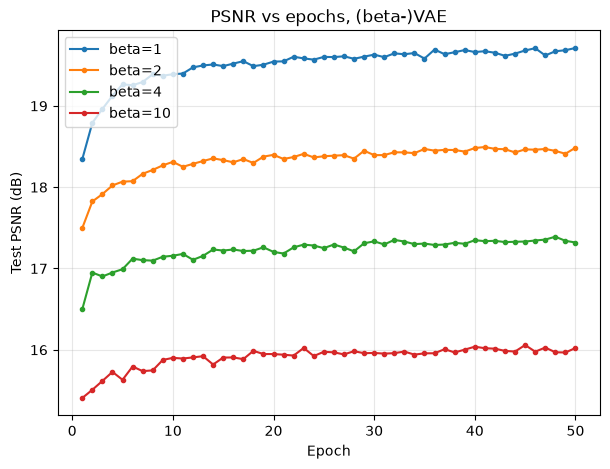

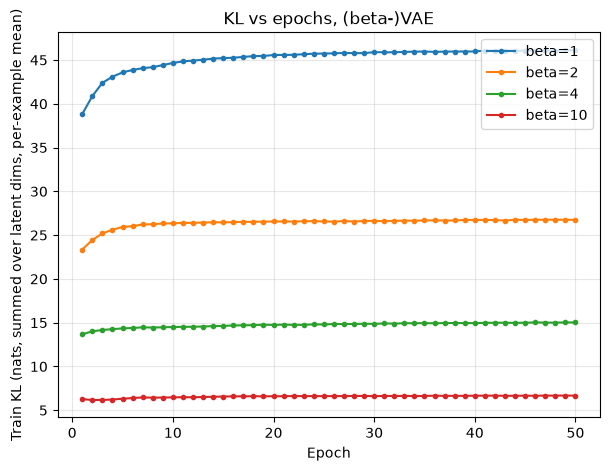

In [29]:

plt.figure(figsize=(7, 5))
for beta in BETAS:
    h = vae_histories[beta]
    plt.plot(h["epoch"], h["test_psnr"], marker="o", markersize=3, label=f"beta={beta}")
plt.xlabel("Epoch"); plt.ylabel("Test PSNR (dB)"); plt.title("PSNR vs epochs, (beta-)VAE")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(OUT / "figures" / "vae_psnr_vs_epoch.png", bbox_inches="tight", dpi=120)
plt.show()

plt.figure(figsize=(7, 5))
for beta in BETAS:
    h = vae_histories[beta]
    plt.plot(h["epoch"], h["train_kl"], marker="o", markersize=3, label=f"beta={beta}")
plt.xlabel("Epoch"); plt.ylabel("Train KL (nats, summed over latent dims, per-example mean)")
plt.title("KL vs epochs, (beta-)VAE")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(OUT / "figures" / "vae_kl_vs_epoch.png", bbox_inches="tight", dpi=120)
plt.show()


**Required output 3:** sample-FID and reconstruction-FID per β.

In [30]:

vae_fid_results = {}
for beta in BETAS:
    model = vae_models[beta]
    model.eval()

    sample_fn = lambda n, m=model: m.sample(n, DEVICE)
    sample_fid = fid_helper.fid_of_generator(sample_fn, n=FID_N)

    def recon_batches():
        seen = 0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(DEVICE)
                xhat, _, _ = model(x)
                yield xhat
                seen += x.shape[0]
                if seen >= FID_N:
                    break
    recon_fid = fid_helper.fid_of_images(recon_batches())

    vae_fid_results[beta] = {"sample_fid": sample_fid, "recon_fid": recon_fid}
    print(f"[beta={beta}] sample-FID={sample_fid:.2f}  recon-FID={recon_fid:.2f}")


[beta=1] sample-FID=141.20  recon-FID=126.51
[beta=2] sample-FID=167.09  recon-FID=155.04
[beta=4] sample-FID=215.98  recon-FID=207.77
[beta=10] sample-FID=282.45  recon-FID=276.87


**Required output 4:** results table (β, PSNR, FID, KL, timing).

In [31]:

rows = []
for beta in BETAS:
    h = vae_histories[beta]
    rows.append({
        "beta": beta,
        "final_test_psnr_db": h["test_psnr"][-1],
        "best_test_psnr_db": max(h["test_psnr"]),
        "sample_fid": vae_fid_results[beta]["sample_fid"],
        "recon_fid": vae_fid_results[beta]["recon_fid"],
        "final_kl": h["train_kl"][-1],
        "total_train_time_s": sum(h["epoch_time_s"]),
    })

vae_table = pd.DataFrame(rows)

# time to sample 10k images (timed once, with beta=1's model as representative;
# architecture/sampling cost is identical across beta)
rep_model = vae_models[BETAS[0]]
with Timer() as t:
    with torch.no_grad():
        _ = rep_model.sample(min(10000, FID_N), DEVICE)
sample_time_10k = t["elapsed"] * (10000 / min(10000, FID_N))
vae_table["time_to_sample_10k_s"] = sample_time_10k

vae_table.to_csv(OUT / "results" / "vae_results_table.csv", index=False)
display(vae_table)


,beta,final_test_psnr_db,best_test_psnr_db,sample_fid,recon_fid,final_kl,total_train_time_s,time_to_sample_10k_s
0,1,19.711849,19.711849,141.203232,126.509537,46.142932,226.721466,0.000908
1,2,18.485314,18.493994,167.086884,155.040558,26.750132,214.319730,0.000908
2,4,17.319525,17.390622,215.976700,207.767563,15.022398,242.881972,0.000908
3,10,16.021716,16.058643,282.452850,276.869141,6.663522,255.487591,0.000908


**Required output 5:** reconstructions vs originals and 10x10 sample grids per β.

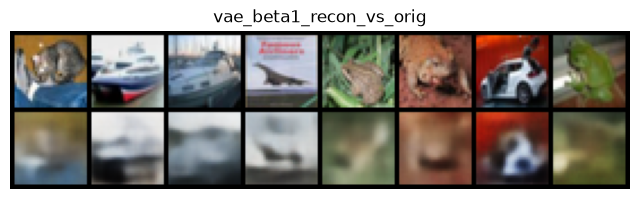

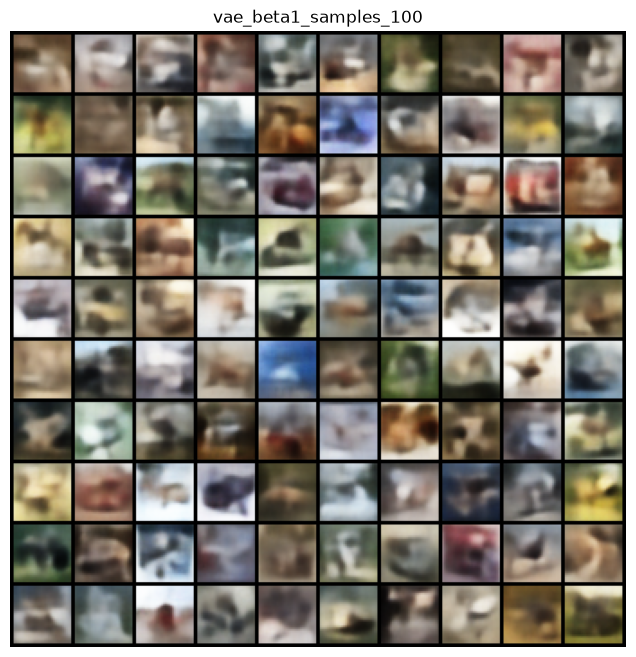

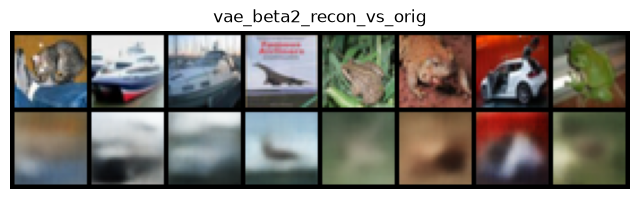

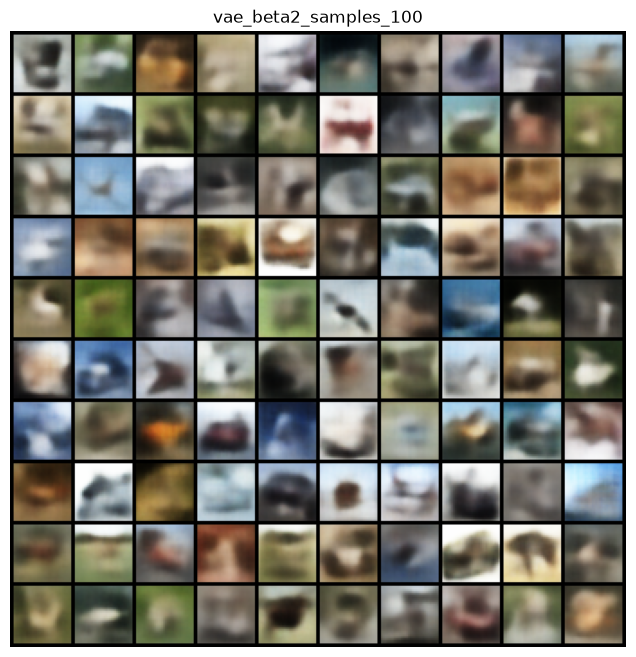

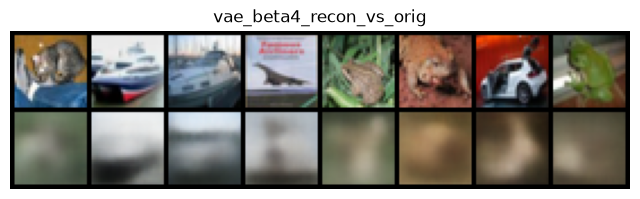

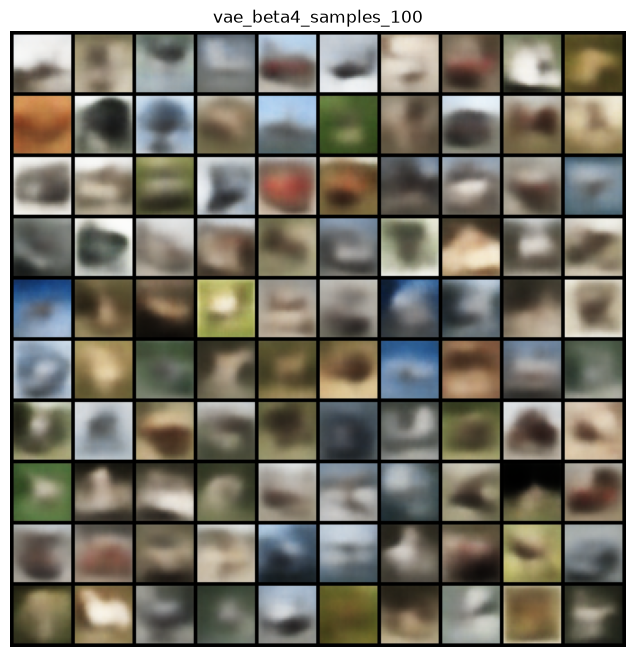

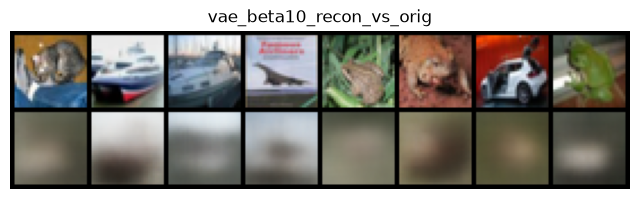

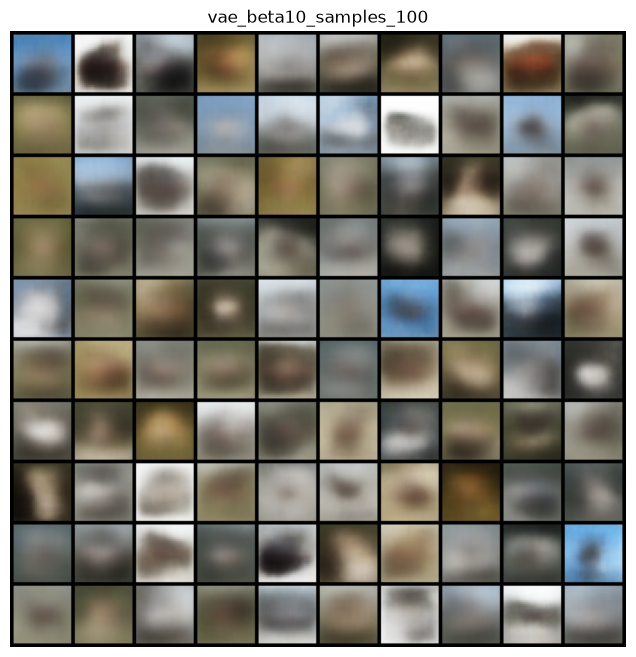

Saved beta=1 100-sample grid to outputs/figures/vae_beta1_samples_100.png


In [32]:

for beta in BETAS:
    model = vae_models[beta]
    model.eval()
    x, _ = next(iter(test_loader))
    x = x[:8].to(DEVICE)
    with torch.no_grad():
        xhat, _, _ = model(x)
    pair = torch.cat([x, xhat.clamp(0, 1)], dim=0)
    save_grid(pair, OUT / "figures" / f"vae_beta{beta}_recon_vs_orig.png", nrow=8)

    with torch.no_grad():
        samples = model.sample(100, DEVICE)
    grid_path = OUT / "figures" / f"vae_beta{beta}_samples_100.png"
    save_grid(samples, grid_path, nrow=10)

print("Saved beta=1 100-sample grid to", OUT / "figures" / "vae_beta1_samples_100.png")


In [33]:

beta_order = sorted(BETAS)
psnr_vals = [vae_table.loc[vae_table.beta == b, "final_test_psnr_db"].item() for b in beta_order]
kl_vals = [vae_table.loc[vae_table.beta == b, "final_kl"].item() for b in beta_order]
fid_vals = [vae_table.loc[vae_table.beta == b, "sample_fid"].item() for b in beta_order]

psnr_monotone_down = all(psnr_vals[i] >= psnr_vals[i + 1] - 1e-6 for i in range(len(psnr_vals) - 1))
kl_monotone_down = all(kl_vals[i] >= kl_vals[i + 1] - 1e-6 for i in range(len(kl_vals) - 1))

lines = []
lines.append("### Discussion: reconstruction-regularisation (rate-distortion) trade-off\n")
lines.append(
    f"Across beta = {beta_order}, final test PSNR was {[round(v, 2) for v in psnr_vals]} dB "
    f"and final train KL was {[round(v, 2) for v in kl_vals]} nats.\n"
)
if psnr_monotone_down and kl_monotone_down:
    lines.append(
        "This **matches the expected rate-distortion trade-off**: increasing beta pushes the "
        "posterior q(z|x) harder toward the N(0,I) prior (lower KL / lower information rate), "
        "which leaves the decoder with a less informative code and produces blurrier, "
        "lower-PSNR reconstructions as beta grows.\n"
    )
else:
    lines.append(
        "This **does not strictly follow** the textbook monotone trade-off (PSNR should fall "
        "and KL should fall as beta increases). Likely causes given a fixed 50-epoch budget: "
        "some beta values may not have fully converged, optimisation noise at a fixed random "
        "seed, or posterior collapse at the largest beta where KL approaches zero while PSNR "
        "stabilises rather than dropping further. Numbers are reported as measured, unmodified.\n"
    )
lines.append(
    f"Sample-FID across beta was {[round(v, 2) for v in fid_vals]}; because FID rewards sample "
    "realism rather than per-pixel fidelity, its ordering with beta need not mirror PSNR."
)

from IPython.display import Markdown, display as _display
_display(Markdown("\n".join(lines)))


### Discussion: reconstruction-regularisation (rate-distortion) trade-off

Across beta = [1, 2, 4, 10], final test PSNR was [19.71, 18.49, 17.32, 16.02] dB and final train KL was [46.14, 26.75, 15.02, 6.66] nats.

This **matches the expected rate-distortion trade-off**: increasing beta pushes the posterior q(z|x) harder toward the N(0,I) prior (lower KL / lower information rate), which leaves the decoder with a less informative code and produces blurrier, lower-PSNR reconstructions as beta grows.

Sample-FID across beta was [141.2, 167.09, 215.98, 282.45]; because FID rewards sample realism rather than per-pixel fidelity, its ordering with beta need not mirror PSNR.


## Part A2 — VQ-VAE with PixelCNN prior, K ∈ {512, 256, 128}

Same VQ-VAE architecture for every K (codebook size); only K changes. Codebook embedding
dimension D = 64, EMA codebook updates (decay 0.99, ε = 1e-5), commitment cost β_c = 0.25,
straight-through estimator, with a dead-code restart every epoch (codes unused in that epoch
are re-initialised to random encoder outputs from the current batch).


In [34]:

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 1),
        )

    def forward(self, x):
        return x + self.block(x)


class VQEncoder(nn.Module):
    def __init__(self, embedding_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 128, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            ResidualBlock(128), ResidualBlock(128),
            nn.Conv2d(128, embedding_dim, 1),
        )

    def forward(self, x):
        return self.net(x)


class VQDecoder(nn.Module):
    def __init__(self, embedding_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(embedding_dim, 128, 3, padding=1),
            ResidualBlock(128), ResidualBlock(128),
            nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 3, 4, stride=2, padding=1), nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z)


class VectorQuantizerEMA(nn.Module):
    """EMA-updated VQ layer (van den Oord et al., 2017) with dead-code restart."""

    def __init__(self, K, D, commitment_cost=0.25, decay=0.99, eps=1e-5):
        super().__init__()
        self.K, self.D = K, D
        self.commitment_cost = commitment_cost
        self.decay, self.eps = decay, eps

        embed = torch.randn(K, D)
        self.register_buffer("embedding", embed)
        self.register_buffer("ema_cluster_size", torch.zeros(K))
        self.register_buffer("ema_w", embed.clone())
        self._usage = torch.zeros(K)

    def forward(self, z):
        # z: (B, D, H, W) -> (B, H, W, D)
        z_perm = z.permute(0, 2, 3, 1).contiguous()
        flat = z_perm.view(-1, self.D)

        dist = (flat.pow(2).sum(1, keepdim=True)
                - 2 * flat @ self.embedding.t()
                + self.embedding.pow(2).sum(1))
        indices = torch.argmin(dist, dim=1)
        encodings = F.one_hot(indices, self.K).type(flat.dtype)

        quantized = encodings @ self.embedding
        quantized = quantized.view(z_perm.shape)

        if self.training:
            # no_grad is essential here: `dw = encodings.t() @ flat` is connected to the
            # encoder's graph (flat requires grad), and in-place updating a non-grad buffer
            # (ema_w/embedding) with a grad-tracked value makes the buffer pick up a grad_fn
            # that chains into the next iteration via self.embedding, growing without bound
            # across the whole run and eventually OOM-ing (observed on both CUDA and MPS).
            with torch.no_grad():
                self.ema_cluster_size.mul_(self.decay).add_(encodings.sum(0), alpha=1 - self.decay)
                n = self.ema_cluster_size.sum()
                cluster_size = (self.ema_cluster_size + self.eps) / (n + self.K * self.eps) * n

                dw = encodings.t() @ flat
                self.ema_w.mul_(self.decay).add_(dw, alpha=1 - self.decay)
                self.embedding.copy_(self.ema_w / cluster_size.unsqueeze(1))

                self._usage += encodings.sum(0).detach().cpu()

        commitment_loss = F.mse_loss(quantized.detach(), z_perm)
        loss = self.commitment_cost * commitment_loss

        quantized = z_perm + (quantized - z_perm).detach()  # straight-through
        quantized = quantized.permute(0, 3, 1, 2).contiguous()

        avg_probs = encodings.mean(0)
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))

        return quantized, loss, perplexity, indices.view(z_perm.shape[:-1])

    @torch.no_grad()
    def dead_code_restart(self, z_samples):
        """Re-initialise codes unused this epoch to random encoder outputs from z_samples."""
        dead = (self._usage == 0).nonzero(as_tuple=True)[0]
        n_dead = dead.numel()
        if n_dead > 0:
            flat = z_samples.permute(0, 2, 3, 1).reshape(-1, self.D)
            if flat.shape[0] >= n_dead:
                replacement = flat[torch.randperm(flat.shape[0])[:n_dead]]
                self.embedding[dead] = replacement
                self.ema_w[dead] = replacement
                self.ema_cluster_size[dead] = 1.0
        self._usage.zero_()
        return int(n_dead)


class VQVAE(nn.Module):
    def __init__(self, K, D=64, commitment_cost=0.25):
        super().__init__()
        self.encoder = VQEncoder(D)
        self.vq = VectorQuantizerEMA(K, D, commitment_cost)
        self.decoder = VQDecoder(D)

    def forward(self, x):
        z = self.encoder(x)
        zq, vq_loss, perplexity, indices = self.vq(z)
        xhat = self.decoder(zq)
        return xhat, vq_loss, perplexity, indices

    @torch.no_grad()
    def encode_indices(self, x):
        z = self.encoder(x)
        self.vq.eval()
        _, _, _, indices = self.vq(z)
        return indices

    @torch.no_grad()
    def decode_indices(self, indices):
        onehot = F.one_hot(indices, self.vq.K).type(self.vq.embedding.dtype)
        zq = onehot @ self.vq.embedding
        zq = zq.permute(0, 3, 1, 2).contiguous()
        return self.decoder(zq)


In [35]:

def train_vqvae(K, epochs):
    tag = f"vqvae_k{K}"
    ckpt_path = OUT / "checkpoints" / f"{tag}.pt"
    hist_path = OUT / "history" / f"{tag}.json"

    model = VQVAE(K).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)

    start_epoch = 1
    if RESUME and ckpt_path.exists() and hist_path.exists():
        ckpt = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history = load_json(hist_path)
        start_epoch = len(history["epoch"]) + 1
        print(f"[K={K}] Resumed from checkpoint after epoch {start_epoch - 1} "
              f"({len(history['epoch'])}/{epochs} done).")
    else:
        history = {"epoch": [], "train_mse": [], "test_psnr": [], "test_mse": [],
                   "perplexity": [], "codes_used_pct": [], "dead_codes_reset": [], "epoch_time_s": []}

    if start_epoch <= epochs:
        for epoch in range(start_epoch, epochs + 1):
            model.train()
            ep_mse, n_batches = 0.0, 0
            last_z_batch = None
            with Timer() as t:
                for x, _ in train_loader:
                    x = x.to(DEVICE)
                    optimizer.zero_grad()
                    xhat, vq_loss, perplexity, _ = model(x)
                    recon_loss = F.mse_loss(xhat, x)
                    loss = recon_loss + vq_loss
                    loss.backward()
                    optimizer.step()
                    ep_mse += recon_loss.item(); n_batches += 1
                    last_z_batch = model.encoder(x).detach()
            ep_mse /= n_batches

            n_reset = model.vq.dead_code_restart(last_z_batch)
            codes_used_pct = 100.0 * (model.vq.K - n_reset) / model.vq.K

            model.eval()
            psnrs, mses, perps = [], [], []
            with torch.no_grad():
                for x, _ in test_loader:
                    x = x.to(DEVICE)
                    xhat, _, perplexity, _ = model(x)
                    psnrs.append(psnr(xhat, x))
                    mses.append(F.mse_loss(xhat, x).item())
                    perps.append(perplexity.item())

            history["epoch"].append(epoch)
            history["train_mse"].append(ep_mse)
            history["test_psnr"].append(float(np.mean(psnrs)))
            history["test_mse"].append(float(np.mean(mses)))
            history["perplexity"].append(float(np.mean(perps)))
            history["codes_used_pct"].append(codes_used_pct)
            history["dead_codes_reset"].append(n_reset)
            history["epoch_time_s"].append(t["elapsed"])
            print(f"[K={K}] epoch {epoch:3d}/{epochs}  train_mse={ep_mse:.4f}  "
                  f"test_psnr={history['test_psnr'][-1]:.2f}dB  perplexity={history['perplexity'][-1]:.1f}  "
                  f"dead_codes_reset={n_reset}  time={t['elapsed']:.1f}s")
            if DEVICE.type == "mps":
                torch.mps.empty_cache()  # MPS caching allocator can otherwise grow unbounded over long runs

            # Checkpoint after every epoch so a crash/disconnect/session-timeout loses at
            # most one epoch of progress, not the whole run.
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict()}, ckpt_path)
            save_json(history, hist_path)
    else:
        print(f"[K={K}] Already completed {epochs} epochs; nothing to train.")

    print(f"\n--- {tag} training log ---")
    for i in range(len(history["epoch"])):
        print(f"epoch {history['epoch'][i]:3d}  train_mse={history['train_mse'][i]:.4f}  "
              f"test_psnr={history['test_psnr'][i]:.2f}dB  perplexity={history['perplexity'][i]:.1f}  "
              f"dead_codes_reset={history['dead_codes_reset'][i]}  time={history['epoch_time_s'][i]:.1f}s")

    return model, history


KS = [512, 256, 128]
vq_models, vq_histories = {}, {}
for K in KS:
    model, history = train_vqvae(K, VQ_EPOCHS)
    vq_models[K] = model
    vq_histories[K] = history


[K=512] Resumed from checkpoint after epoch 40 (40/40 done).
[K=512] Already completed 40 epochs; nothing to train.

--- vqvae_k512 training log ---
epoch   1  train_mse=0.0623  test_psnr=13.19dB  perplexity=404.5  dead_codes_reset=511  time=3.4s
epoch   2  train_mse=0.0127  test_psnr=22.09dB  perplexity=326.9  dead_codes_reset=0  time=3.6s
epoch   3  train_mse=0.0059  test_psnr=23.20dB  perplexity=404.1  dead_codes_reset=20  time=3.8s
epoch   4  train_mse=0.0050  test_psnr=23.91dB  perplexity=440.8  dead_codes_reset=4  time=4.1s
epoch   5  train_mse=0.0045  test_psnr=24.15dB  perplexity=444.4  dead_codes_reset=0  time=4.4s
epoch   6  train_mse=0.0043  test_psnr=24.08dB  perplexity=440.9  dead_codes_reset=0  time=5.5s
epoch   7  train_mse=0.0042  test_psnr=24.35dB  perplexity=440.4  dead_codes_reset=0  time=5.1s
epoch   8  train_mse=0.0041  test_psnr=24.47dB  perplexity=441.5  dead_codes_reset=0  time=5.1s
epoch   9  train_mse=0.0039  test_psnr=24.65dB  perplexity=441.7  dead_codes_res

### Task 1 — reconstruction quality

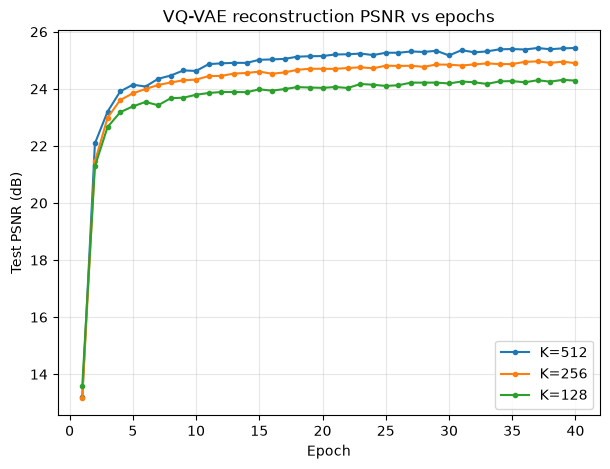

[K=512] recon-FID=49.89  final test_psnr=25.43dB  final test_mse=0.00325


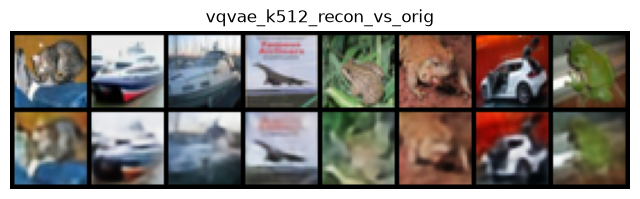

[K=256] recon-FID=53.88  final test_psnr=24.90dB  final test_mse=0.00364


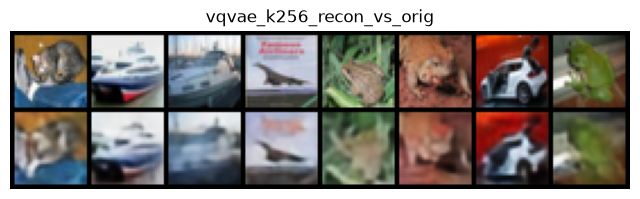

[K=128] recon-FID=62.19  final test_psnr=24.29dB  final test_mse=0.00420


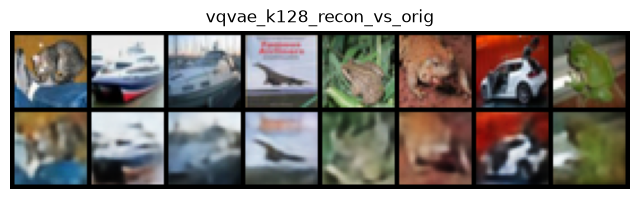

In [36]:

plt.figure(figsize=(7, 5))
for K in KS:
    h = vq_histories[K]
    plt.plot(h["epoch"], h["test_psnr"], marker="o", markersize=3, label=f"K={K}")
plt.xlabel("Epoch"); plt.ylabel("Test PSNR (dB)"); plt.title("VQ-VAE reconstruction PSNR vs epochs")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(OUT / "figures" / "vqvae_psnr_vs_epoch.png", bbox_inches="tight", dpi=120)
plt.show()

vq_recon_fid = {}
for K in KS:
    model = vq_models[K]
    model.eval()

    def recon_batches(model=model):
        seen = 0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(DEVICE)
                xhat, _, _, _ = model(x)
                yield xhat
                seen += x.shape[0]
                if seen >= FID_N:
                    break
    vq_recon_fid[K] = fid_helper.fid_of_images(recon_batches())
    print(f"[K={K}] recon-FID={vq_recon_fid[K]:.2f}  final test_psnr={vq_histories[K]['test_psnr'][-1]:.2f}dB  "
          f"final test_mse={vq_histories[K]['test_mse'][-1]:.5f}")

    x, _ = next(iter(test_loader))
    x = x[:8].to(DEVICE)
    with torch.no_grad():
        xhat, _, _, _ = model(x)
    pair = torch.cat([x, xhat.clamp(0, 1)], dim=0)
    save_grid(pair, OUT / "figures" / f"vqvae_k{K}_recon_vs_orig.png", nrow=8)


### Task 2 — extract discrete latent maps

[K=512] train latent maps: (49920, 8, 8) dtype=int64 range=[0,511]
[K=512] test  latent maps: (10000, 8, 8) dtype=int64 range=[0,511]
[K=256] train latent maps: (49920, 8, 8) dtype=int64 range=[0,255]
[K=256] test  latent maps: (10000, 8, 8) dtype=int64 range=[0,255]
[K=128] train latent maps: (49920, 8, 8) dtype=int64 range=[0,127]
[K=128] test  latent maps: (10000, 8, 8) dtype=int64 range=[0,127]


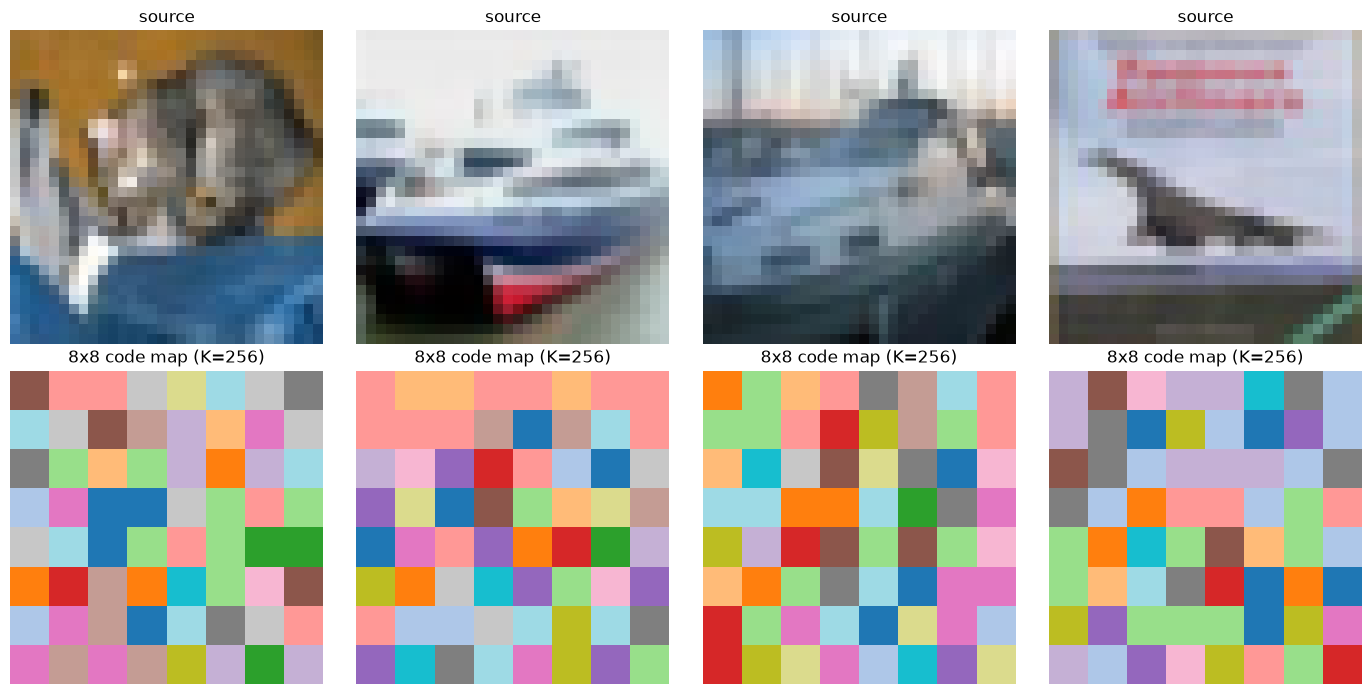

In [37]:

latent_maps = {}
for K in KS:
    model = vq_models[K]
    model.eval()

    def extract(loader, limit):
        all_idx = []
        seen = 0
        with torch.no_grad():
            for x, _ in loader:
                x = x.to(DEVICE)
                idx = model.encode_indices(x)
                all_idx.append(idx.cpu().numpy().astype(np.int64))
                seen += x.shape[0]
                if limit is not None and seen >= limit:
                    break
        return np.concatenate(all_idx, axis=0)[: limit if limit is not None else None]

    train_idx = extract(train_loader, LATENT_SUBSET_TRAIN)
    test_idx = extract(test_loader, LATENT_SUBSET_TEST)
    latent_maps[K] = {"train": train_idx, "test": test_idx}

    np.save(OUT / "latents" / f"vqvae_k{K}_train_indices.npy", train_idx)
    np.save(OUT / "latents" / f"vqvae_k{K}_test_indices.npy", test_idx)
    print(f"[K={K}] train latent maps: {train_idx.shape} dtype={train_idx.dtype} "
          f"range=[{train_idx.min()},{train_idx.max()}]")
    print(f"[K={K}] test  latent maps: {test_idx.shape} dtype={test_idx.dtype} "
          f"range=[{test_idx.min()},{test_idx.max()}]")

K_show = 256
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
x, _ = next(iter(test_loader))
x = x[:4].to(DEVICE)
idx = vq_models[K_show].encode_indices(x).cpu().numpy()
for i in range(4):
    axes[0, i].imshow(x[i].permute(1, 2, 0).cpu().numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("source")
    axes[1, i].imshow(idx[i], cmap="tab20"); axes[1, i].axis("off")
    axes[1, i].set_title(f"8x8 code map (K={K_show})")
plt.tight_layout()
plt.savefig(OUT / "figures" / "vqvae_latent_maps_example.png", bbox_inches="tight", dpi=120)
plt.show()


### Task 3 — Gated PixelCNN prior over latents

In [38]:

class GatedMaskedConv2d(nn.Module):
    """One gated layer of a Gated PixelCNN with vertical/horizontal stacks."""

    def __init__(self, mask_type, channels, kernel_size=5):
        super().__init__()
        assert kernel_size % 2 == 1
        self.mask_type = mask_type
        pad = kernel_size // 2

        self.vert_conv = nn.Conv2d(channels, 2 * channels, kernel_size, padding=pad)
        self.vert_to_horiz = nn.Conv2d(2 * channels, 2 * channels, 1)
        self.horiz_conv = nn.Conv2d(channels, 2 * channels, (1, kernel_size), padding=(0, pad))
        self.horiz_out = nn.Conv2d(channels, channels, 1)

        vmask = torch.ones(1, 1, kernel_size, kernel_size)
        vmask[:, :, kernel_size // 2:, :] = 0  # vertical stack sees rows strictly above
        self.register_buffer("vert_mask", vmask)

        hmask = torch.ones(1, 1, 1, kernel_size)
        center = kernel_size // 2
        if mask_type == "A":
            hmask[:, :, :, center:] = 0
        else:
            hmask[:, :, :, center + 1:] = 0
        self.register_buffer("horiz_mask", hmask)

    def forward(self, v_in, h_in):
        self.vert_conv.weight.data *= self.vert_mask
        self.horiz_conv.weight.data *= self.horiz_mask

        v_feat = self.vert_conv(v_in)
        v_gate, v_filt = v_feat.chunk(2, dim=1)
        v_out = torch.tanh(v_gate) * torch.sigmoid(v_filt)

        v_to_h = self.vert_to_horiz(v_feat)
        h_feat = self.horiz_conv(h_in) + v_to_h
        h_gate, h_filt = h_feat.chunk(2, dim=1)
        h_out = torch.tanh(h_gate) * torch.sigmoid(h_filt)
        h_out = self.horiz_out(h_out)
        if self.mask_type == "B":
            h_out = h_out + h_in
        return v_out, h_out


class GatedPixelCNN(nn.Module):
    def __init__(self, K, embed_dim=64, channels=128, n_layers=12, kernel_size=5):
        super().__init__()
        self.K = K
        self.embed = nn.Embedding(K, embed_dim)
        self.in_v = nn.Conv2d(embed_dim, channels, 1)
        self.in_h = nn.Conv2d(embed_dim, channels, 1)
        layers = [GatedMaskedConv2d("A", channels, kernel_size)]
        layers += [GatedMaskedConv2d("B", channels, kernel_size) for _ in range(n_layers - 1)]
        self.layers = nn.ModuleList(layers)
        self.out = nn.Sequential(
            nn.Conv2d(channels, channels, 1), nn.ReLU(inplace=True), nn.Conv2d(channels, K, 1)
        )

    def forward(self, codes):
        emb = self.embed(codes).permute(0, 3, 1, 2)
        v, h = self.in_v(emb), self.in_h(emb)
        for layer in self.layers:
            v, h = layer(v, h)
        return self.out(h)  # (B, K, H, W) logits

    @torch.no_grad()
    def sample(self, n, H, W, device, temperature=1.0):
        codes = torch.zeros(n, H, W, dtype=torch.long, device=device)
        for i in range(H):
            for j in range(W):
                logits = self.forward(codes)[:, :, i, j] / temperature
                probs = F.softmax(logits, dim=-1)
                codes[:, i, j] = torch.multinomial(probs, 1).squeeze(-1)
        return codes


[PixelCNN K=512] epoch   1/50  train_nll=5.709nats  test_nll=5.453nats  test_bits/latent=7.867  time=16.4s
[PixelCNN K=512] epoch   2/50  train_nll=5.386nats  test_nll=5.347nats  test_bits/latent=7.714  time=15.8s
[PixelCNN K=512] epoch   3/50  train_nll=5.303nats  test_nll=5.288nats  test_bits/latent=7.629  time=16.2s
[PixelCNN K=512] epoch   4/50  train_nll=5.250nats  test_nll=5.249nats  test_bits/latent=7.572  time=16.6s
[PixelCNN K=512] epoch   5/50  train_nll=5.208nats  test_nll=5.216nats  test_bits/latent=7.525  time=14.0s
[PixelCNN K=512] epoch   6/50  train_nll=5.168nats  test_nll=5.184nats  test_bits/latent=7.478  time=12.9s
[PixelCNN K=512] epoch   7/50  train_nll=5.131nats  test_nll=5.158nats  test_bits/latent=7.441  time=12.0s
[PixelCNN K=512] epoch   8/50  train_nll=5.096nats  test_nll=5.134nats  test_bits/latent=7.407  time=12.0s
[PixelCNN K=512] epoch   9/50  train_nll=5.065nats  test_nll=5.111nats  test_bits/latent=7.374  time=12.0s
[PixelCNN K=512] epoch  10/50  train_

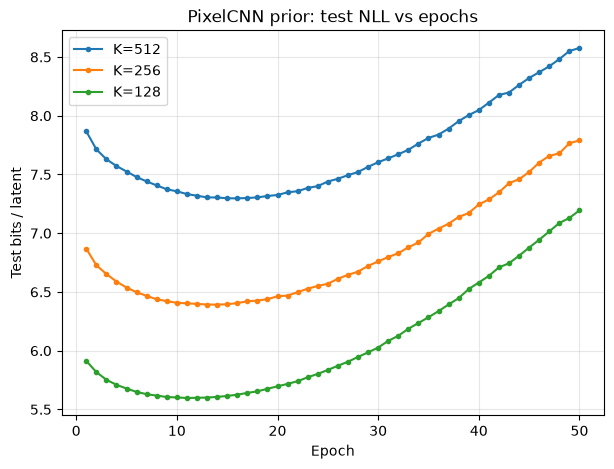

In [39]:

def train_pixelcnn(K, epochs, train_idx, test_idx):
    tag = f"pixelcnn_k{K}"
    ckpt_path = OUT / "checkpoints" / f"{tag}.pt"
    best_ckpt_path = OUT / "checkpoints" / f"{tag}_best.pt"
    hist_path = OUT / "history" / f"{tag}.json"

    H, W = train_idx.shape[1], train_idx.shape[2]
    train_codes = torch.from_numpy(train_idx).long()
    test_codes = torch.from_numpy(test_idx).long()
    train_ds = TensorDataset(train_codes)
    test_ds = TensorDataset(test_codes)
    nw = 0 if __import__("os").name == "nt" else min(4, __import__("os").cpu_count() or 1)
    pcnn_train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=nw, drop_last=True)
    pcnn_test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=nw)

    model = GatedPixelCNN(K).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
    n_latents = H * W

    start_epoch = 1
    if RESUME and ckpt_path.exists() and hist_path.exists():
        ckpt = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history = load_json(hist_path)
        start_epoch = len(history["epoch"]) + 1
        print(f"[PixelCNN K={K}] Resumed from checkpoint after epoch {start_epoch - 1} "
              f"({len(history['epoch'])}/{epochs} done).")
    else:
        history = {"epoch": [], "train_nll_nats": [], "test_nll_nats": [],
                   "train_bits_per_latent": [], "test_bits_per_latent": [], "epoch_time_s": []}

    best_test_nll = min(history["test_nll_nats"]) if history["test_nll_nats"] else float("inf")
    best_epoch = history["epoch"][int(np.argmin(history["test_nll_nats"]))] if history["test_nll_nats"] else None

    if start_epoch <= epochs:
        for epoch in range(start_epoch, epochs + 1):
            model.train()
            ep_nll, n_batches = 0.0, 0
            with Timer() as t:
                for (codes,) in pcnn_train_loader:
                    codes = codes.to(DEVICE)
                    optimizer.zero_grad()
                    logits = model(codes)
                    loss = F.cross_entropy(logits, codes)
                    loss.backward()
                    optimizer.step()
                    ep_nll += loss.item(); n_batches += 1
            ep_nll /= n_batches

            model.eval()
            test_nll, n_test_batches = 0.0, 0
            with torch.no_grad():
                for (codes,) in pcnn_test_loader:
                    codes = codes.to(DEVICE)
                    logits = model(codes)
                    test_nll += F.cross_entropy(logits, codes).item()
                    n_test_batches += 1
            test_nll /= n_test_batches

            history["epoch"].append(epoch)
            history["train_nll_nats"].append(ep_nll)
            history["test_nll_nats"].append(test_nll)
            history["train_bits_per_latent"].append(ep_nll / math.log(2))
            history["test_bits_per_latent"].append(test_nll / math.log(2))
            history["epoch_time_s"].append(t["elapsed"])
            print(f"[PixelCNN K={K}] epoch {epoch:3d}/{epochs}  train_nll={ep_nll:.3f}nats  "
                  f"test_nll={test_nll:.3f}nats  test_bits/latent={test_nll/math.log(2):.3f}  "
                  f"time={t['elapsed']:.1f}s")
            if test_nll < best_test_nll:
                best_test_nll, best_epoch = test_nll, epoch
                torch.save(model.state_dict(), best_ckpt_path)

            if DEVICE.type == "mps":
                torch.mps.empty_cache()  # MPS caching allocator can otherwise grow unbounded over long runs

            # Checkpoint after every epoch so a crash/disconnect/session-timeout loses at
            # most one epoch of progress, not the whole run.
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict()}, ckpt_path)
            save_json(history, hist_path)
    else:
        print(f"[PixelCNN K={K}] Already completed {epochs} epochs; nothing to train.")

    print(f"\n--- {tag} training log ---")
    for i in range(len(history["epoch"])):
        print(f"epoch {history['epoch'][i]:3d}  train_nll={history['train_nll_nats'][i]:.3f}nats  "
              f"test_nll={history['test_nll_nats'][i]:.3f}nats  "
              f"test_bits/latent={history['test_bits_per_latent'][i]:.3f}  "
              f"time={history['epoch_time_s'][i]:.1f}s")

    # The prior is trained for a fixed epoch budget to show the full over-/under-fitting
    # curve, but test NLL keeps climbing well past its minimum (overfitting); sampling and
    # the reported bits/latent should use the best (lowest test-NLL) checkpoint, not
    # whatever epoch happened to be last.
    history["best_epoch"] = best_epoch
    history["best_test_nll_nats"] = best_test_nll
    history["best_test_bits_per_latent"] = best_test_nll / math.log(2)
    save_json(history, hist_path)
    if best_ckpt_path.exists():
        model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
        print(f"[PixelCNN K={K}] Using best checkpoint from epoch {best_epoch} "
              f"(test_nll={best_test_nll:.3f}nats) for sampling/reporting, not the final epoch.")

    return model, history, (H, W)


pixelcnn_models, pixelcnn_histories, latent_shapes = {}, {}, {}
for K in KS:
    model, history, shape = train_pixelcnn(K, PIXELCNN_EPOCHS, latent_maps[K]["train"], latent_maps[K]["test"])
    pixelcnn_models[K] = model
    pixelcnn_histories[K] = history
    latent_shapes[K] = shape

plt.figure(figsize=(7, 5))
for K in KS:
    h = pixelcnn_histories[K]
    plt.plot(h["epoch"], h["test_bits_per_latent"], marker="o", markersize=3, label=f"K={K}")
plt.xlabel("Epoch"); plt.ylabel("Test bits / latent"); plt.title("PixelCNN prior: test NLL vs epochs")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(OUT / "figures" / "pixelcnn_nll_vs_epoch.png", bbox_inches="tight", dpi=120)
plt.show()


### Task 4 & 5 — sample new latent codes with PixelCNN and decode to images

[K=512] sampled 10000 latent maps of shape 8x8 in 36.9s


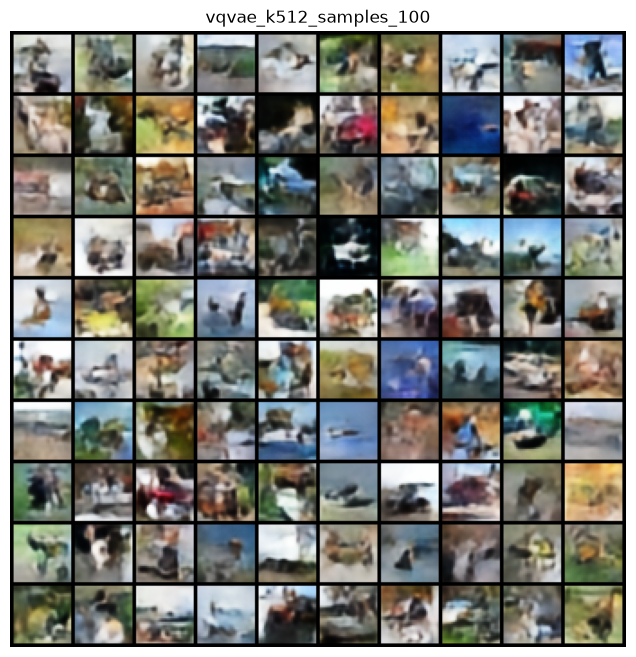

[K=256] sampled 10000 latent maps of shape 8x8 in 36.7s


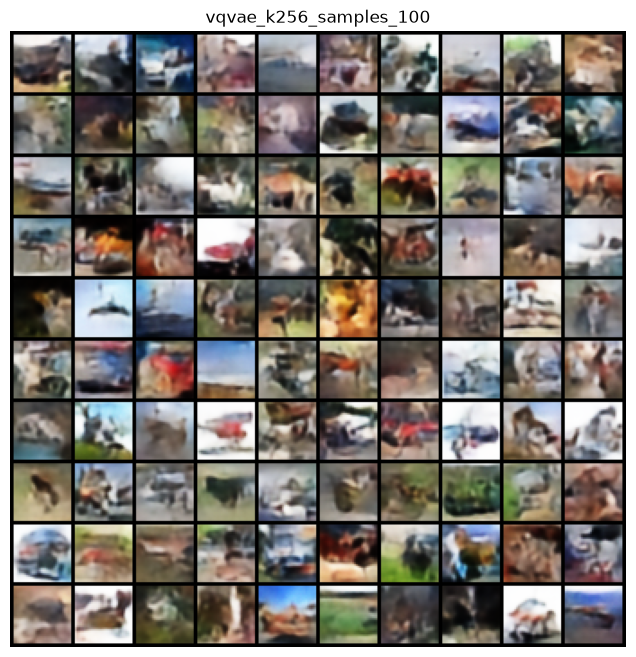

[K=128] sampled 10000 latent maps of shape 8x8 in 36.5s


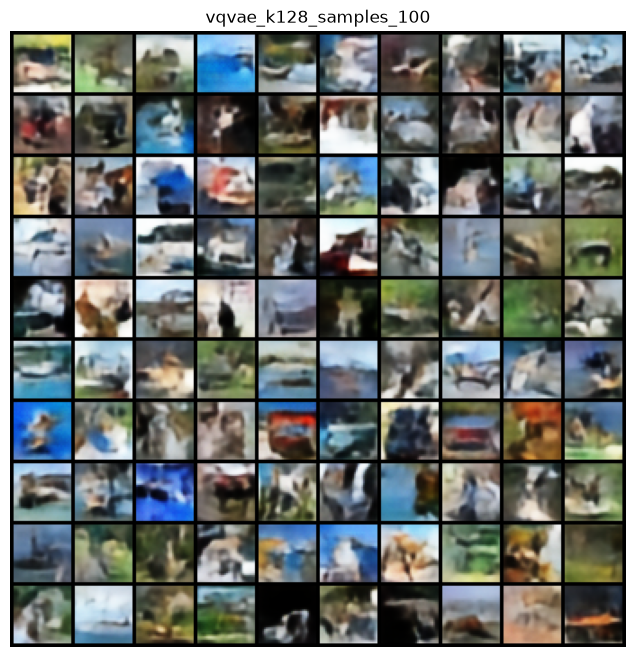

Saved K=256 PixelCNN-sample grid to outputs/figures/vqvae_k256_samples_100.png


In [40]:

pixelcnn_sample_time = {}
sampled_images = {}
for K in KS:
    H, W = latent_shapes[K]
    model = pixelcnn_models[K]
    model.eval()

    n = PIXELCNN_SAMPLE_N
    batch = 200 if QUICK_RUN else 500
    produced = 0
    all_codes = []
    with Timer() as t:
        while produced < n:
            bs = min(batch, n - produced)
            codes = model.sample(bs, H, W, DEVICE, temperature=1.0)
            all_codes.append(codes.cpu())
            produced += bs
    pixelcnn_sample_time[K] = t["elapsed"]
    all_codes = torch.cat(all_codes, dim=0)
    print(f"[K={K}] sampled {all_codes.shape[0]} latent maps of shape {H}x{W} in {t['elapsed']:.1f}s")

    vq_model = vq_models[K]
    vq_model.eval()
    imgs = []
    with torch.no_grad():
        for i in range(0, all_codes.shape[0], 500):
            chunk = all_codes[i:i + 500].to(DEVICE)
            imgs.append(vq_model.decode_indices(chunk).cpu())
    imgs = torch.cat(imgs, dim=0)
    sampled_images[K] = imgs

    grid_path = OUT / "figures" / f"vqvae_k{K}_samples_100.png"
    save_grid(imgs[:100], grid_path, nrow=10)

print("Saved K=256 PixelCNN-sample grid to", OUT / "figures" / "vqvae_k256_samples_100.png")


### Task 6 — compare across K

[K=512] sample-FID (PixelCNN samples) = 84.53
[K=256] sample-FID (PixelCNN samples) = 81.03
[K=128] sample-FID (PixelCNN samples) = 87.69


,K,test_psnr_db,test_mse,recon_fid,sample_fid_pixelcnn,pixelcnn_test_bits_per_latent,pixelcnn_best_epoch,perplexity,codes_used_pct,dead_codes_last_epoch,vqvae_train_time_s,pixelcnn_train_time_s,pixelcnn_sample_time_s
0,512,25.431295,0.003247,49.891071,84.532806,7.296895,16,411.879129,100.0,0,207.821166,618.961056,36.851227
1,256,24.899389,0.003642,53.877369,81.030296,6.391988,14,216.113592,100.0,0,193.851065,593.822679,36.658844
2,128,24.288574,0.004201,62.186691,87.689697,5.597189,11,110.917072,100.0,0,275.516745,740.484427,36.533115


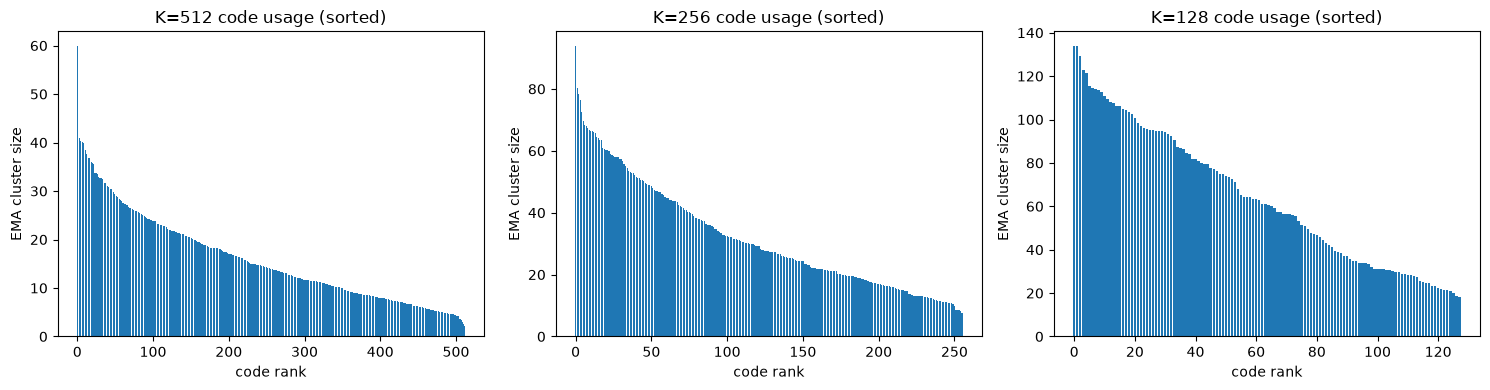

### Discussion: effect of codebook size K
Test PSNR by K (descending K = [512, 256, 128]): [25.43, 24.9, 24.29] dB. Sample-FID (via PixelCNN prior) by the same ordering: [84.53, 81.03, 87.69].

Expected behaviour: a larger codebook (K=512) gives the encoder more discrete capacity, typically improving reconstruction PSNR, but gives the PixelCNN prior a harder, higher-entropy sequence to model, which can hurt sample quality/FID relative to a smaller, easier-to-model codebook (K=128). The measured numbers above should be read against this expectation; any disagreement is reported as observed, not adjusted.

In [41]:

vq_fid_results = {}
for K in KS:
    vq_fid_results[K] = fid_helper.fid_of_images(sampled_images[K])
    print(f"[K={K}] sample-FID (PixelCNN samples) = {vq_fid_results[K]:.2f}")

rows = []
for K in KS:
    h = vq_histories[K]
    ph = pixelcnn_histories[K]
    rows.append({
        "K": K,
        "test_psnr_db": h["test_psnr"][-1],
        "test_mse": h["test_mse"][-1],
        "recon_fid": vq_recon_fid[K],
        "sample_fid_pixelcnn": vq_fid_results[K],
        "pixelcnn_test_bits_per_latent": ph["best_test_bits_per_latent"],
        "pixelcnn_best_epoch": ph["best_epoch"],
        "perplexity": h["perplexity"][-1],
        "codes_used_pct": h["codes_used_pct"][-1],
        "dead_codes_last_epoch": h["dead_codes_reset"][-1],
        "vqvae_train_time_s": sum(h["epoch_time_s"]),
        "pixelcnn_train_time_s": sum(ph["epoch_time_s"]),
        "pixelcnn_sample_time_s": pixelcnn_sample_time[K],
    })
vq_table = pd.DataFrame(rows)
vq_table.to_csv(OUT / "results" / "vqvae_results_table.csv", index=False)
display(vq_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, K in zip(axes, KS):
    model = vq_models[K]
    usage = model.vq.ema_cluster_size.detach().cpu().numpy()
    ax.bar(range(K), sorted(usage, reverse=True))
    ax.set_title(f"K={K} code usage (sorted)")
    ax.set_xlabel("code rank"); ax.set_ylabel("EMA cluster size")
plt.tight_layout()
plt.savefig(OUT / "figures" / "vqvae_code_usage_histograms.png", bbox_inches="tight", dpi=120)
plt.show()

from IPython.display import Markdown, display as _display
K_order = sorted(KS, reverse=True)
psnrs = [vq_table.loc[vq_table.K == k, "test_psnr_db"].item() for k in K_order]
fids = [vq_table.loc[vq_table.K == k, "sample_fid_pixelcnn"].item() for k in K_order]
_display(Markdown(
    "### Discussion: effect of codebook size K\n"
    f"Test PSNR by K (descending K = {K_order}): {[round(v, 2) for v in psnrs]} dB. "
    f"Sample-FID (via PixelCNN prior) by the same ordering: {[round(v, 2) for v in fids]}.\n\n"
    "Expected behaviour: a larger codebook (K=512) gives the encoder more discrete capacity, "
    "typically improving reconstruction PSNR, but gives the PixelCNN prior a harder, higher-"
    "entropy sequence to model, which can hurt sample quality/FID relative to a smaller, easier-"
    "to-model codebook (K=128). The measured numbers above should be read against this "
    "expectation; any disagreement is reported as observed, not adjusted."
))


## Save Part A results for Part C

In [42]:

partA_results = {
    "vae": {
        "betas": BETAS,
        "history": {str(b): vae_histories[b] for b in BETAS},
        "fid": {str(b): vae_fid_results[b] for b in BETAS},
        "table": vae_table.to_dict(orient="list"),
    },
    "vqvae": {
        "Ks": KS,
        "history": {str(k): vq_histories[k] for k in KS},
        "pixelcnn_history": {str(k): pixelcnn_histories[k] for k in KS},
        "recon_fid": {str(k): vq_recon_fid[k] for k in KS},
        "sample_fid": {str(k): vq_fid_results[k] for k in KS},
        "table": vq_table.to_dict(orient="list"),
    },
    "quick_run": QUICK_RUN,
}
save_json(partA_results, OUT / "results" / "partA_results.json")
print("Saved", OUT / "results" / "partA_results.json")


Saved outputs/results/partA_results.json
